In [76]:
import numpy as np
import sys, os, shutil
import matplotlib.pyplot as plt
from scipy.constants import lambda2nu, nu2lambda, c
from scipy.optimize import curve_fit
from scipy.interpolate import PchipInterpolator, CubicSpline
lumapiFile = "C:\\Program Files\\Lumerical\\v261\\api\\python\\lumapi.py"

import importlib.util
import sys

spec = importlib.util.spec_from_file_location("lumapi", lumapiFile)
lumapi = importlib.util.module_from_spec(spec)
sys.modules["lumapi"] = lumapi
spec.loader.exec_module(lumapi)

import lumapi

In [77]:
from IPython.core.display import HTML
from IPython.display import display, Math
from IPython.core.pylabtools import figsize

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

figsize(8, 4)

In [78]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
lambda0 = 1550*nm
f0 = c/lambda0

## Parametros do guia de onda

w = 500*nm
h = 220*nm

material = 'Si (Silicon) - Palik'
sub_material = 'SiO2 (Glass) - Palik'

## Parametros do anel

R = 114*um
gap = 200*nm

## Parametros do solver

lambda_min = 1500*nm
lambda_max = 1600*nm
number_of_frequency_points = 51
mesh_accuracy = 4

indxLambda = 24

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

## Atividade 3 ##

In [79]:
fdtdApi = lumapi.FDTD(hide=False)

### Montado o acoplador halfring ###

In [80]:
fdtdApi.deleteall()

x_span = 50*um
theta_start = 180/pi * np.arcsin((R-12*w+gap)/R)
theta_stop = 180 - theta_start

fdtdApi.addring()
fdtdApi.set('name', 'meio anel')
fdtdApi.set('theta start', theta_start)
fdtdApi.set('theta stop', theta_stop)
fdtdApi.set('z span', h)
fdtdApi.set('outer radius', R + w/2)
fdtdApi.set('inner radius', R - w/2)
fdtdApi.set('material', material)
fdtdApi.set('first axis', 'z')
fdtdApi.set('rotation 1', 180)
fdtdApi.set('x', 0)
fdtdApi.set('y', 0)
fdtdApi.set('z', 0)

fdtdApi.addrect()
fdtdApi.set('name', 'guia reto')
fdtdApi.set('material', material)
fdtdApi.set('x span', x_span)
fdtdApi.set('y span', w)
fdtdApi.set('z span', h)
fdtdApi.set('x', 0)
fdtdApi.set('y', -(R+w+gap))
fdtdApi.set('z', 0)

# solver

fdtdApi.addfdtd()
fdtdApi.set('background material', sub_material)
fdtdApi.set('mesh accuracy', mesh_accuracy)
fdtdApi.set('global source wavelength start', lambda_min)
fdtdApi.set('global source wavelength stop', lambda_max)
fdtdApi.set('global monitor frequency points', number_of_frequency_points)
fdtdApi.set('global monitor frequency points', number_of_frequency_points)
fdtdApi.set('simulation time', 7*x_span/c)
fdtdApi.set('x', 0)
fdtdApi.set('x span', x_span-1*um)
fdtdApi.set('y min', -(R+6*w+gap))
fdtdApi.set('y max', -(R-12*w+gap))
fdtdApi.set('z', 0)
fdtdApi.set('z span', 3*h)

fdtdApi.addport()
fdtdApi.set('name', 'porta 1')
fdtdApi.set('injection axis', 'x')
fdtdApi.set('direction', 'Forward')
fdtdApi.set('x', -x_span/2+1.5*um)
fdtdApi.set('y', -(R+w+gap))
fdtdApi.set('z', 0)
fdtdApi.set('y span', 7*w)
fdtdApi.set('z span', 2.5*h)

fdtdApi.addport()
fdtdApi.set('name', 'porta 2')
fdtdApi.set('injection axis', 'x-axis')
fdtdApi.set('direction', 'Backward')
fdtdApi.set('x', x_span/2-1.5*um)
fdtdApi.set('y', -(R+w+gap))
fdtdApi.set('z', 0)
fdtdApi.set('y span', 7*w)
fdtdApi.set('z span', 2.5*h)

# monitores

fdtdApi.addprofile()
fdtdApi.set('name', 'profile_xy')
fdtdApi.set('override global monitor settings', True)
fdtdApi.set('frequency points', number_of_frequency_points)
fdtdApi.set('x', 0)
fdtdApi.set('x span', x_span-1*um)
fdtdApi.set('y min', -(R+6*w+gap))
fdtdApi.set('y max', -(R-12*w+gap))
fdtdApi.set('z', 0)

fdtdApi.addindex()
fdtdApi.set('name', 'index')
fdtdApi.set('x', 0)
fdtdApi.set('x span', x_span-1*um)
fdtdApi.set('y min', -(R+6*w+gap))
fdtdApi.set('y max', -(R-12*w+gap))
fdtdApi.set('z', 0)


fdtdApi.setdevice('GPU')

fdtdApi.setnamed('FDTD::ports', 'source port', 'porta 1')

fdtdApi.save('acoplador halfring')

### Simulando ###

In [81]:
fdtdApi.run()

### Visualizando os gráficos e campos ###

In [82]:
index_x = np.squeeze(fdtdApi.getdata('index', 'index_x').real)
x_device = np.squeeze(fdtdApi.getdata('index', 'x'))/um
y_device = np.squeeze(fdtdApi.getdata('index', 'y'))/um

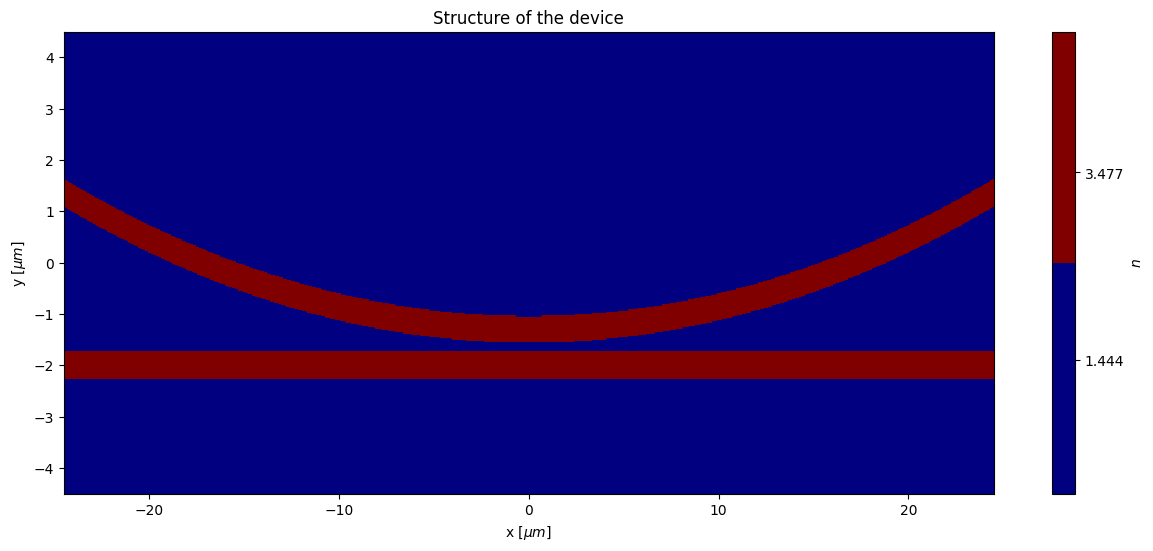

In [83]:
X, Y = np.meshgrid(x_device, y_device - (np.min(y_device)+np.max(y_device))/2)
X, Y = np.transpose(X), np.transpose(Y)
v = np.linspace(np.min(index_x), np.max(index_x), 2)

fig0 = plt.figure(figsize=(15,6))
im0 = plt.contourf(X, Y, index_x, 0, cmap = plt.get_cmap('jet'), vmin = v[0], vmax = v[-1], origin = 'lower')
colorbar = plt.colorbar(im0, label = r'$n$')
colorbar.set_ticks(v)
plt.xlabel(r'x [$\mu m$]')
plt.ylabel(r'y [$\mu m$]')
plt.title('Structure of the device')

plt.show()

In [84]:
eField_x = np.squeeze(fdtdApi.getdata('profile_xy', 'Ex'))
eField_y = np.squeeze(fdtdApi.getdata('profile_xy', 'Ey'))
eField_z = np.squeeze(fdtdApi.getdata('profile_xy', 'Ez'))

eField_abs2_Signal = np.abs(eField_x)**2 + np.abs(eField_y)**2 + np.abs(eField_z)**2
eField_abs_Signal = np.sqrt(eField_abs2_Signal)

x_efield = fdtdApi.getdata('profile_xy', 'x')
y_efield = fdtdApi.getdata('profile_xy', 'y')
y_efield = y_efield - (np.min(y_efield) + np.max(y_efield))/2
wavelength = nu2lambda(fdtdApi.getdata('profile_xy', 'f'))
xmin = np.min(x_efield) / um
xmax = np.max(x_efield) / um
ymin = np.min(y_efield) / um
ymax = np.max(y_efield) / um

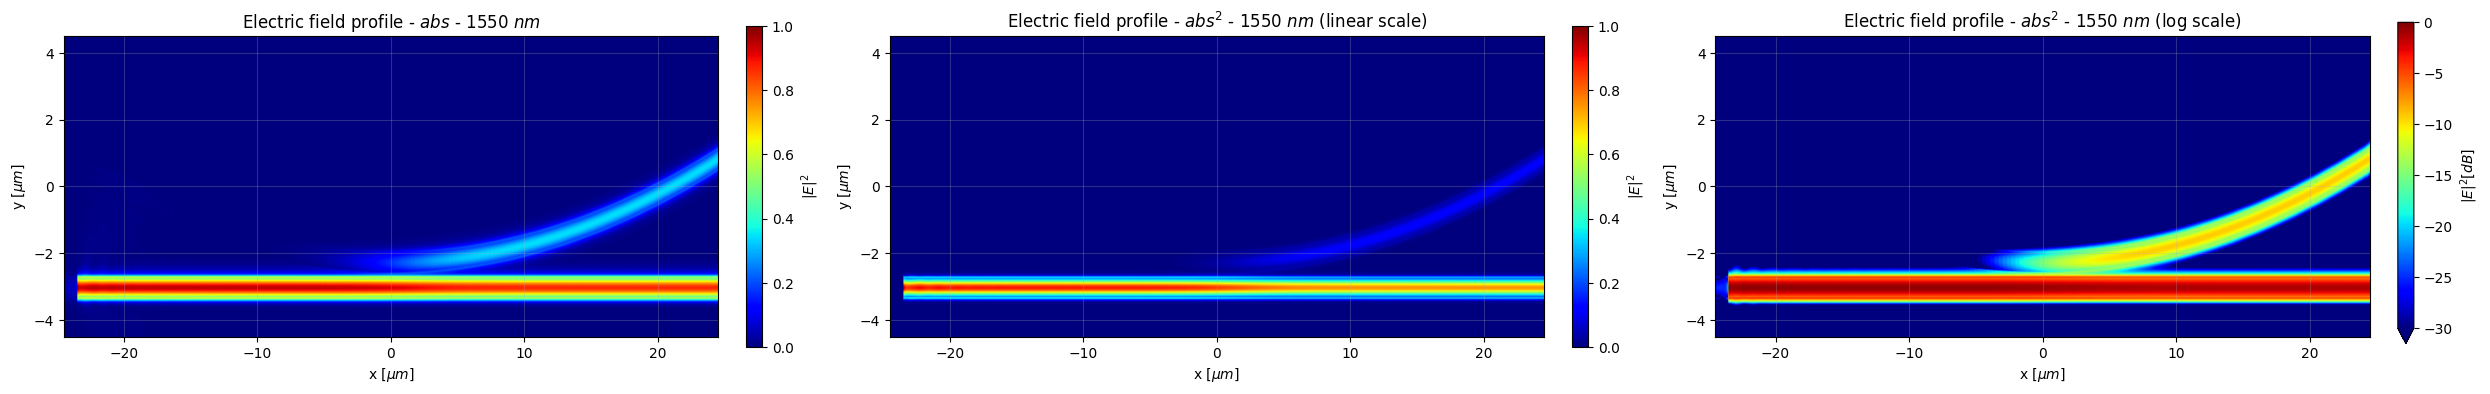

In [85]:
fig1, ax1 = plt.subplots(1,3,figsize=(25,5))

im1 = ax1[0].imshow(np.rot90(eField_abs_Signal[:,:,indxLambda]), extent=[xmin, xmax, ymin, ymax], vmin = 0, vmax = 1, cmap = 'jet', aspect = 2.5)
#ticks_linear = np.linspace(0, 1, 11)

colorbar = plt.colorbar(im1,fraction = 0.023, pad =0.04, label = r'$|E|^2$')

ax1[0].set_xlabel(r'x [$\mu m$]')
ax1[0].set_ylabel(r'y [$\mu m$]')
ax1[0].set_title(r'Electric field profile - $abs$ - %d $nm$' % (wavelength[indxLambda,0]/nm))
ax1[0].grid(which='major', alpha = 0.25)

im2 = ax1[1].imshow(np.rot90(eField_abs2_Signal[:,:,indxLambda]), extent=[xmin, xmax, ymin, ymax], vmin = 0, vmax = 1, cmap = 'jet', aspect = 2.5)
ticks_linear = np.linspace(0, 1, 11)

colorbar = plt.colorbar(im2,fraction = 0.023, pad =0.04, label = r'$|E|^2$')

ax1[1].set_xlabel(r'x [$\mu m$]')
ax1[1].set_ylabel(r'y [$\mu m$]')
ax1[1].set_title(r'Electric field profile - $abs^{2}$ - %d $nm$ (linear scale)' % (wavelength[indxLambda,0]/nm))
ax1[1].grid(which='major', alpha = 0.25)

im3 = ax1[2].imshow(np.rot90(10*np.log10(eField_abs2_Signal[:,:,indxLambda])), extent = [xmin, xmax, ymin, ymax], vmin = -30, vmax = 0, cmap = 'jet', aspect = 2.5)

colorbar = plt.colorbar(im3, fraction = 0.023, pad = 0.04, label = r'$|E|^2 [dB]$', extend = 'min')

ax1[2].set_xlabel(r'x [$\mu m$]')
ax1[2].set_ylabel(r'y [$\mu m$]')
ax1[2].set_title(r'Electric field profile - $abs^{2}$ - %d $nm$ (log scale)' % (wavelength[indxLambda,0]/nm))
ax1[2].grid(which='major', alpha = 0.25)

plt.tight_layout()
plt.show()

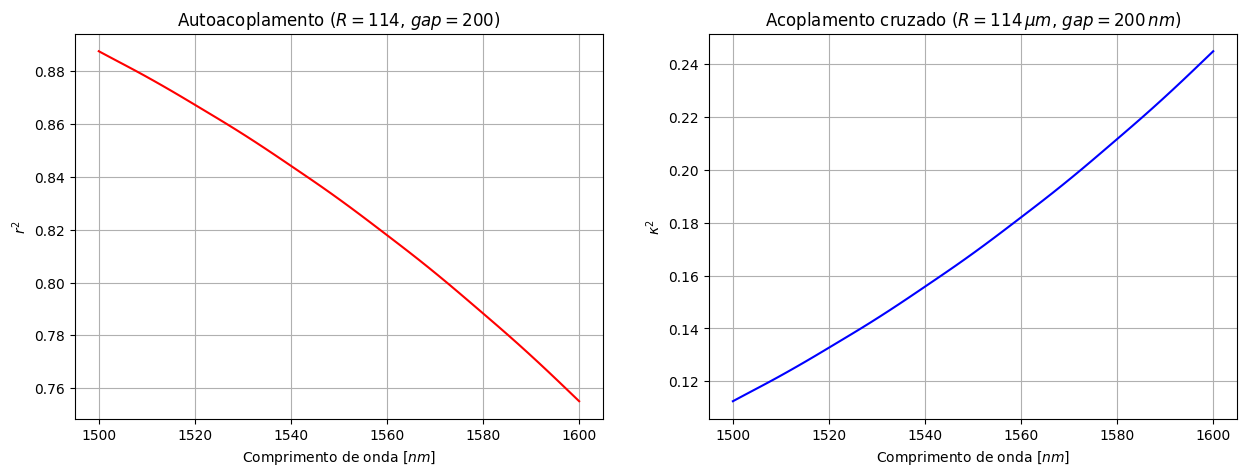

In [86]:
P_input = np.abs(fdtdApi.getresult('FDTD::ports::porta 1', 'T')['T'])
P_out = np.abs(fdtdApi.getresult('FDTD::ports::porta 2', 'T')['T'])

r2 = P_out/P_input
k2 = 1 - r2

fig, ax = plt.subplots(1,2, figsize=(15,5))

ax[0].plot(wavelength/nm, r2, color = 'red')
ax[0].set_xlabel(r'Comprimento de onda [$nm$]')
ax[0].set_ylabel(r'$r^2$')
ax[0].grid(True)
ax[0].set_title(r'Autoacoplamento ($R=%d$, $gap=%d$)' %(R/um, gap/nm))

ax[1].plot(wavelength/nm, k2, color = 'blue')
ax[1].set_xlabel(r'Comprimento de onda [$nm$]')
ax[1].set_ylabel(r'$\kappa^2$')
ax[1].grid(True)
ax[1].set_title(r'Acoplamento cruzado ($R=%d\,\mu m$, $gap=%d\,nm$)' %(R/um, gap/nm))

plt.show()

In [87]:
P_input_center = P_input[indxLambda]
P_out_center = P_out[indxLambda]
r2 = P_out_center/P_input_center
k2 = 1-r2

print('Acoplamento cruzado no comprimento de onda central para g = %d nm: \u03ba² = %.2f' %(gap/nm,k2))

Acoplamento cruzado no comprimento de onda central para g = 200 nm: κ² = 0.17


# Extraindo $\kappa^2(g,R)$ com $R=114\,\mu m$ #

In [88]:
g_array = np.arange(50,250,10)*nm

r2_array = []
for g in g_array:
    fdtdApi.switchtolayout()

    fdtdApi.setnamed('guia reto', 'y', -(R+w+g))
    fdtdApi.run()

    P_input_center = (np.abs(fdtdApi.getresult('FDTD::ports::porta 1', 'T')['T']))[indxLambda]
    P_out_center = (np.abs(fdtdApi.getresult('FDTD::ports::porta 2', 'T')['T']))[indxLambda]
    r2 = P_out_center/P_input_center
    r2_array.append(r2)
r2_array = np.array(r2_array)
k2_array = 1 - r2_array

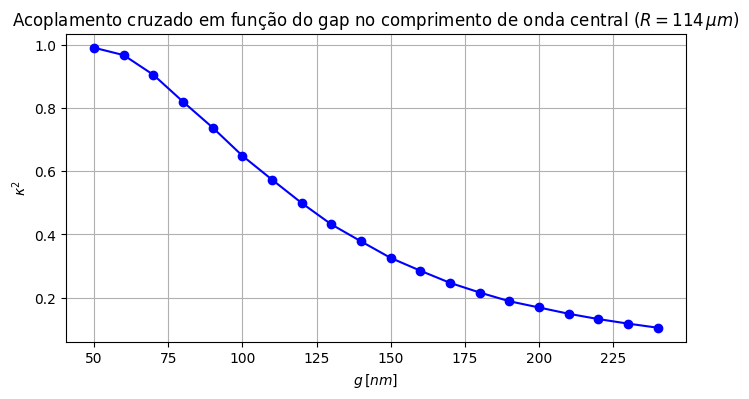

In [89]:
plt.plot(g_array/nm, k2_array, color = 'blue', marker = 'o')
plt.grid(True)
plt.xlabel(r'$g\,[nm]$')
plt.ylabel(r'$\kappa^2$')
plt.title(r'Acoplamento cruzado em função do gap no comprimento de onda central ($R=%d\,\mu m$)' %(R/um))
plt.show()

In [90]:
#acoplamento = CubicSpline(g_array, k2_array)
#gap_para_acoplamento = CubicSpline(np.flip(k2_array), np.flip(g_array))

log_k2 = np.log(k2_array)
log_cs = CubicSpline(g_array, log_k2, extrapolate=False)
inv_log_cs = CubicSpline(np.flip(log_k2), np.flip(g_array), extrapolate=False)

# Taxas de decaimento exponencial nas bordas
d_ini = log_cs(g_array[0], 1)
d_fim = log_cs(g_array[-1], 1)

def acoplamento(g):
    log_val = log_cs(g)
    log_val = np.where(g < g_array[0], log_k2[0] + d_ini * (g - g_array[0]), log_val)
    log_val = np.where(g > g_array[-1], log_k2[-1] + d_fim * (g - g_array[-1]), log_val)
    return np.exp(log_val)

def gap_para_acoplamento(k2):
    log_val = np.log(k2)
    g = inv_log_cs(log_val)
    # Inverso exato das retas de extrapolação nas bordas
    g = np.where(log_val > log_k2[0], g_array[0] + (log_val - log_k2[0]) / d_ini, g)
    g = np.where(log_val < log_k2[-1], g_array[-1] + (log_val - log_k2[-1]) / d_fim, g)
    return g

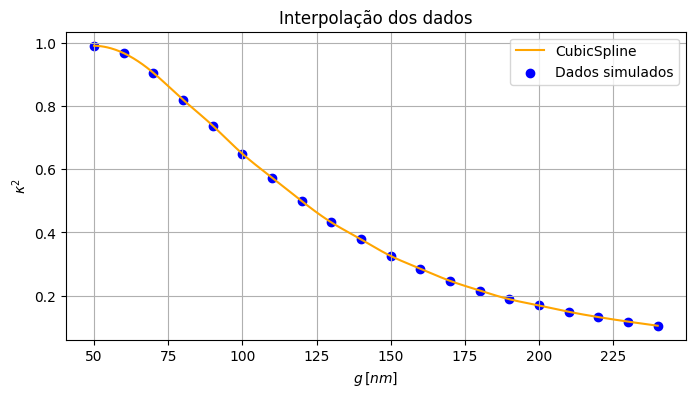

In [91]:
g_array2 = np.linspace(50,240, 501)*nm

plt.plot(g_array2/nm, acoplamento(g_array2), color = 'orange', label = 'CubicSpline')
plt.scatter(g_array/nm, k2_array, color = 'blue', label = 'Dados simulados')
plt.grid(True)
plt.legend(loc='best')
plt.xlabel(r'$g\,[nm]$')
plt.ylabel(r'$\kappa^2$')
plt.title('Interpolação dos dados')
plt.show()

In [96]:
k2_desejado = 0.1239
print('Para \u03ba² = %.4f é necessário g=%d nm.' %(k2_desejado, gap_para_acoplamento(0.1239)/nm))

Para κ² = 0.1239 é necessário g=225 nm.


In [94]:
fdtdApi.close()
os.remove("acoplador halfring.fsp")
os.remove("acoplador halfring_p0.log")
shutil.rmtree('acoplador halfring')